- Nombre: Joel Arturo Alvarez Hernandez
- Matricula: 403233
- Universidad Autonoma de Chihuahua
- Facultad de Ingenieria
- Machine Learning
- Actividad: Proyecto Final
- Docente: Dra. Olanda Prieto Ordaz


Dataset:
- https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data/data

Investigaciones:
- https://www.mdpi.com/2079-8954/13/7/581
- https://rpubs.com/qinnihoo/wqd7004project#:~:text=To%20tackle%20a%20loan%20approval%20classification%20project,for%20obtain%2C%20scrub%2C%20explore%2C%20model%20and%20interpret.
- https://www.researchgate.net/publication/399598089_Journal_of_Smart_Sensors_and_Computing_Loan_Default_Prediction_Using_Ensemble_Machine_Learning_Algorithms
- https://www.researchgate.net/publication/392103275_Loan_Approval_Prediction_Using_Neural_Networks

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import math
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,     precision_recall_curve

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.dummy import DummyClassifier
from cuml.svm import SVC as cuSVC



In [8]:

# 1. Cargar el dataset principal (cambia 'datos_covid.csv' por el nombre real de tu archivo)
print("Cargando datos principales...")
df = pd.read_csv('../loan approval/loan_data.csv')

print(f"Se cargaron {len(df)} registros.")


Cargando datos principales...
Se cargaron 45000 registros.


In [9]:
print(f"Dimensión del main dataset: {df.shape}\n")
df.info()
# Configurar pandas para que muestre TODAS las columnas
pd.set_option('display.max_columns', None)

display(df.head())

print("\n--- Valores faltantes por columna ---")
print(df.isnull().sum())
print(f"\n--- Filas idénticas: {df.duplicated().sum()} ---")

Dimensión del main dataset: (45000, 14)

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  pr

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1



--- Valores faltantes por columna ---
person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

--- Filas idénticas: 0 ---


In [10]:
# Definición de X e y
from sklearn.model_selection import train_test_split


y = df['loan_status']
X = df.drop(columns=['loan_status'])

# Partición Train/Test (80/20)
# Utilizamos stratify=y para mantener la proporción exacta de las clases
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y # para el desbalance de clases
)

df_Train = X_train.copy()
df_Train['loan_status'] = y_train


--- Verificación de la Proporción de Clases ---


,Train (%),Test (%)
Loan Rechazado (Clase 0),77.778,77.778
Loan Aprobado (Clase 1),22.222,22.222


/tmp/ipykernel_991/219493582.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_verificacion.index, y=df_verificacion['Train (%)'], ax=axes[0], palette='Blues')
/tmp/ipykernel_991/219493582.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_verificacion.index, y=df_verificacion['Test (%)'], ax=axes[1], palette='Oranges')


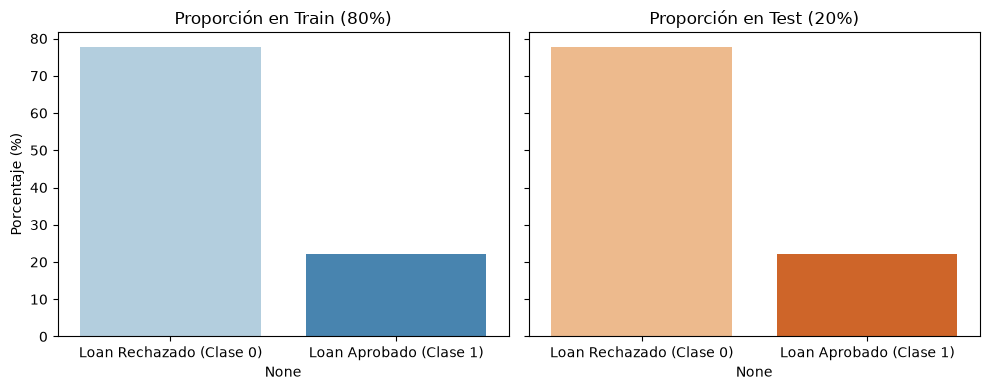

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular las proporciones (porcentajes) en Train y Test
prop_train = pd.Series(y_train).value_counts(normalize=True) * 100
prop_test = pd.Series(y_test).value_counts(normalize=True) * 100

# 2. Crear un DataFrame para comparar frente a frente
df_verificacion = pd.DataFrame({
    'Train (%)': prop_train,
    'Test (%)': prop_test
})

# Crear indices
df_verificacion.index = ['Loan Rechazado (Clase 0)', 'Loan Aprobado (Clase 1)']

print("--- Verificación de la Proporción de Clases ---")
display(df_verificacion.round(3))

# 3. Verificación visual (Gráfica de barras)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

# Gráfica de Train
sns.barplot(x=df_verificacion.index, y=df_verificacion['Train (%)'], ax=axes[0], palette='Blues')
axes[0].set_title('Proporción en Train (80%)')
axes[0].set_ylabel('Porcentaje (%)')

# Gráfica de Test
sns.barplot(x=df_verificacion.index, y=df_verificacion['Test (%)'], ax=axes[1], palette='Oranges')
axes[1].set_title('Proporción en Test (20%)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

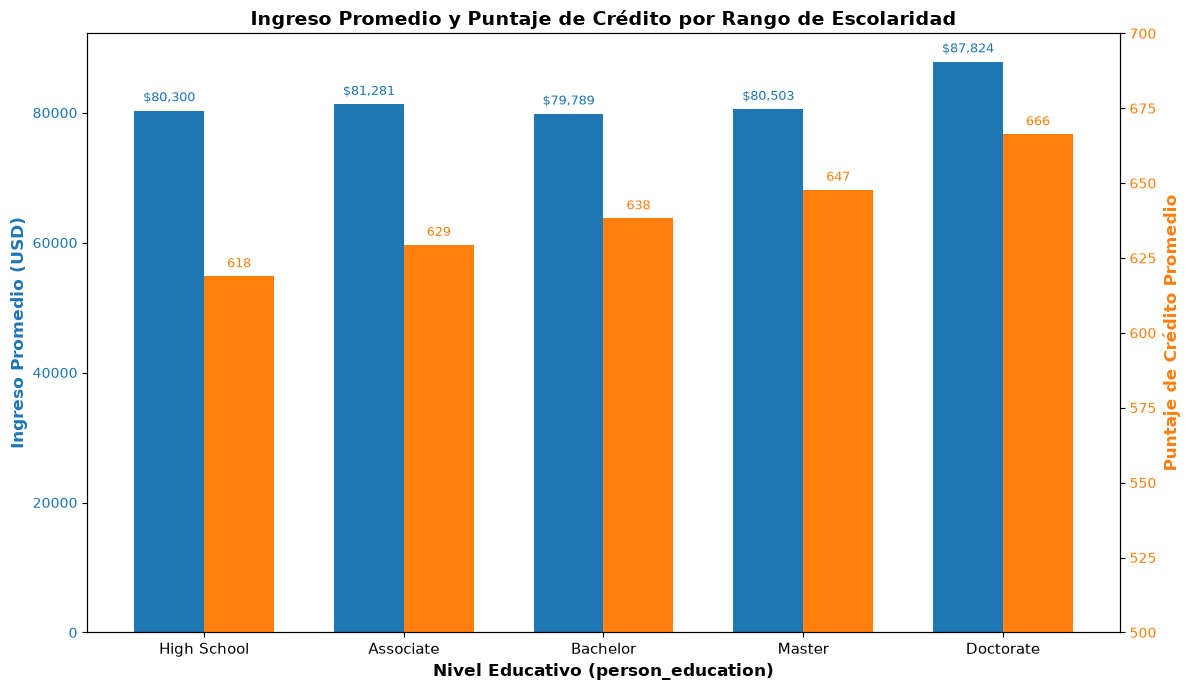

In [6]:
# Definir el orden lógico de la escolaridad (de menor a mayor)
# Convertir la columna a una categoría con el orden específico
orden_educacion = ['High School', 'Associate', 'Bachelor', 'Master', 'Doctorate']
df_Train['person_education'] = pd.Categorical(df_Train['person_education'], categories=orden_educacion, ordered=True)

# Agrupar por nivel educativo y calcular los promedios (ahora respetará el orden)
agg_df = df_Train.groupby('person_education', observed=False)[['person_income', 'credit_score']].mean().reset_index()

# Configurar la figura
fig, ax1 = plt.subplots(figsize=(12, 7))

x = np.arange(len(agg_df['person_education']))
width = 0.35

# --- Eje 1 (Izquierdo): Ingreso Promedio (Azul) ---
color1 = '#1f77b4'
ax1.set_xlabel('Nivel Educativo (person_education)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Ingreso Promedio (USD)', color=color1, fontsize=12, fontweight='bold')
bars1 = ax1.bar(x - width/2, agg_df['person_income'], width, color=color1)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_xticks(x)
ax1.set_xticklabels(agg_df['person_education'], fontsize=11)

# --- Eje 2 (Derecho): Puntaje de Crédito Promedio (Naranja) ---
ax2 = ax1.twinx()
color2 = '#ff7f0e'
ax2.set_ylabel('Puntaje de Crédito Promedio', color=color2, fontsize=12, fontweight='bold')
# Ajustar el límite para que se aprecien las diferencias en el puntaje
ax2.set_ylim(500, 700) 
bars2 = ax2.bar(x + width/2, agg_df['credit_score'], width, color=color2)
ax2.tick_params(axis='y', labelcolor=color2)

# Título principal
plt.title('Ingreso Promedio y Puntaje de Crédito por Rango de Escolaridad', fontsize=14, fontweight='bold')

# Añadir las etiquetas de texto sobre las barras azules (Ingreso)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 1000, 
             f'${int(yval):,}', ha='center', va='bottom', color=color1, fontsize=9)

# Añadir las etiquetas de texto sobre las barras naranjas (Puntaje de Crédito)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 2, 
             f'{int(yval)}', ha='center', va='bottom', color=color2, fontsize=9)

# Ajustar el diseño y mostrar la gráfica
fig.tight_layout()
plt.show()

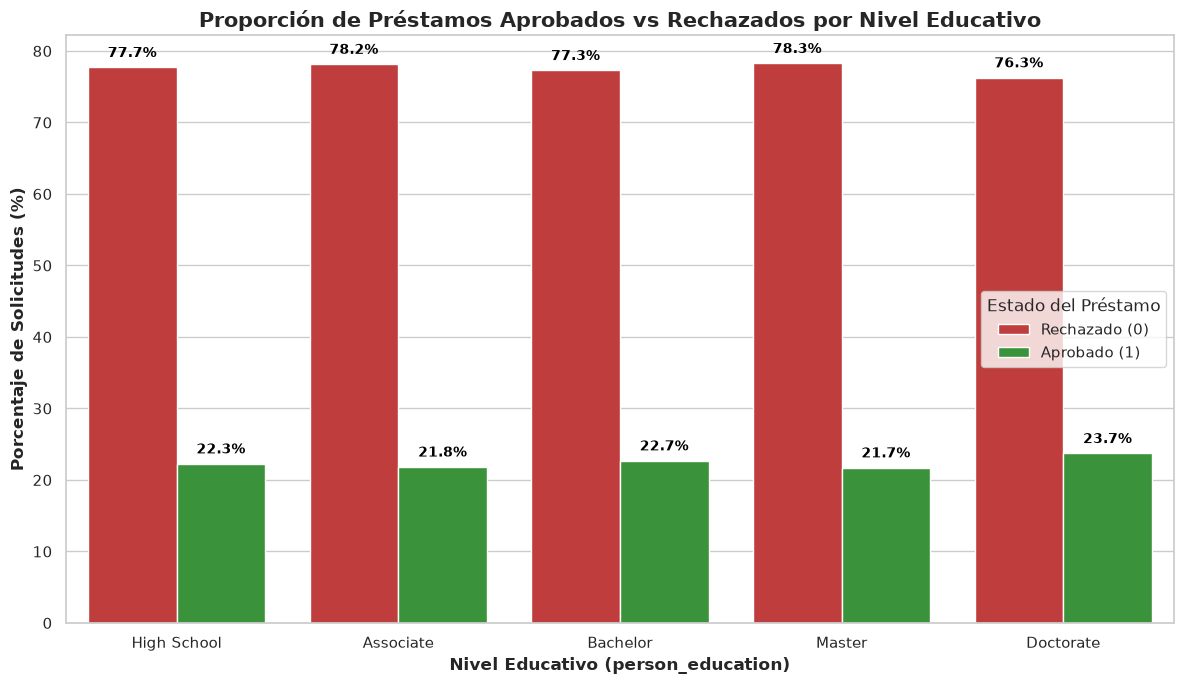

In [7]:
# Agrupar por nivel educativo y estado del préstamo para contar las frecuencias
edu_loan_counts = df_Train.groupby(['person_education', 'loan_status'], observed=False).size().reset_index(name='count')

# Calcular el porcentaje que representa cada estado (0 o 1) dentro de cada nivel educativo
total_por_edu = edu_loan_counts.groupby('person_education', observed=False)['count'].transform('sum')
edu_loan_counts['percentage'] = (edu_loan_counts['count'] / total_por_edu) * 100

# Configurar el tamaño y estilo de la gráfica
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

# Crear el gráfico de barras agrupadas mostrando los porcentajes
grafica = sns.barplot(
    data=edu_loan_counts, 
    x='person_education', 
    y='percentage', 
    hue='loan_status',
    palette={0: '#d62728', 1: '#2ca02c'} # Rojo = Rechazado (0), Verde = Aprobado (1)
)

# Personalizar títulos y etiquetas
plt.title('Proporción de Préstamos Aprobados vs Rechazados por Nivel Educativo', fontsize=15, fontweight='bold')
plt.xlabel('Nivel Educativo (person_education)', fontsize=12, fontweight='bold')
plt.ylabel('Porcentaje de Solicitudes (%)', fontsize=12, fontweight='bold')

# Modificar la leyenda para mayor claridad
handles, _ = grafica.get_legend_handles_labels()
plt.legend(handles=handles, title='Estado del Préstamo', labels=['Rechazado (0)', 'Aprobado (1)'], fontsize=11)

# Añadir los valores de porcentaje en la parte superior de cada barra
for p in grafica.patches:
    height = p.get_height()
    if height > 0: # Evitar poner texto si la barra es 0
        grafica.annotate(f'{height:.1f}%', 
                         (p.get_x() + p.get_width() / 2., height), 
                         ha='center', va='bottom', 
                         fontsize=10, fontweight='bold', color='black', 
                         xytext=(0, 5), textcoords='offset points')

# Ajustar el diseño y mostrar la gráfica
plt.tight_layout()
plt.show()

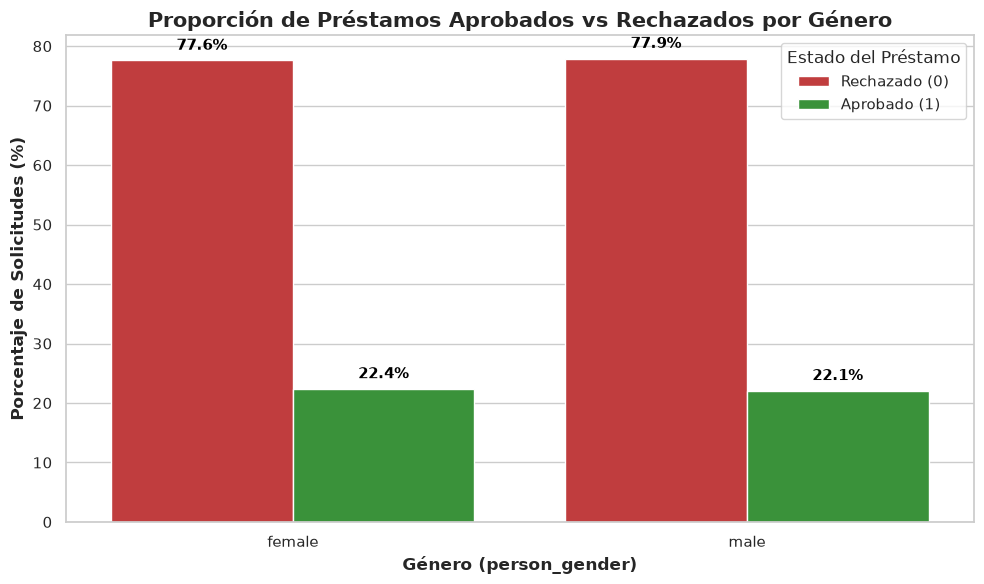

In [8]:


# Agrupar por género y estado del préstamo para contar las frecuencias
gender_loan_counts = df_Train.groupby(['person_gender', 'loan_status'], observed=False).size().reset_index(name='count')

# Calcular el porcentaje que representa cada estado (0 o 1) dentro de cada género
total_por_gender = gender_loan_counts.groupby('person_gender', observed=False)['count'].transform('sum')
gender_loan_counts['percentage'] = (gender_loan_counts['count'] / total_por_gender) * 100

# Configurar el tamaño y estilo de la gráfica
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Crear el gráfico de barras agrupadas mostrando los porcentajes
grafica = sns.barplot(
    data=gender_loan_counts, 
    x='person_gender', 
    y='percentage', 
    hue='loan_status',
    palette={0: '#d62728', 1: '#2ca02c'} # Rojo = Rechazado (0), Verde = Aprobado (1)
)

# Personalizar títulos y etiquetas
plt.title('Proporción de Préstamos Aprobados vs Rechazados por Género', fontsize=15, fontweight='bold')
plt.xlabel('Género (person_gender)', fontsize=12, fontweight='bold')
plt.ylabel('Porcentaje de Solicitudes (%)', fontsize=12, fontweight='bold')

# Modificar la leyenda para mayor claridad
handles, _ = grafica.get_legend_handles_labels()
plt.legend(handles=handles, title='Estado del Préstamo', labels=['Rechazado (0)', 'Aprobado (1)'], fontsize=11)

# Añadir los valores de porcentaje en la parte superior de cada barra
for p in grafica.patches:
    height = p.get_height()
    if height > 0: # Evitar poner texto si la barra es 0
        grafica.annotate(f'{height:.1f}%', 
                         (p.get_x() + p.get_width() / 2., height), 
                         ha='center', va='bottom', 
                         fontsize=11, fontweight='bold', color='black', 
                         xytext=(0, 5), textcoords='offset points')

# Ajustar el diseño y mostrar la gráfica
plt.tight_layout()
plt.show()

/tmp/ipykernel_886/173709250.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


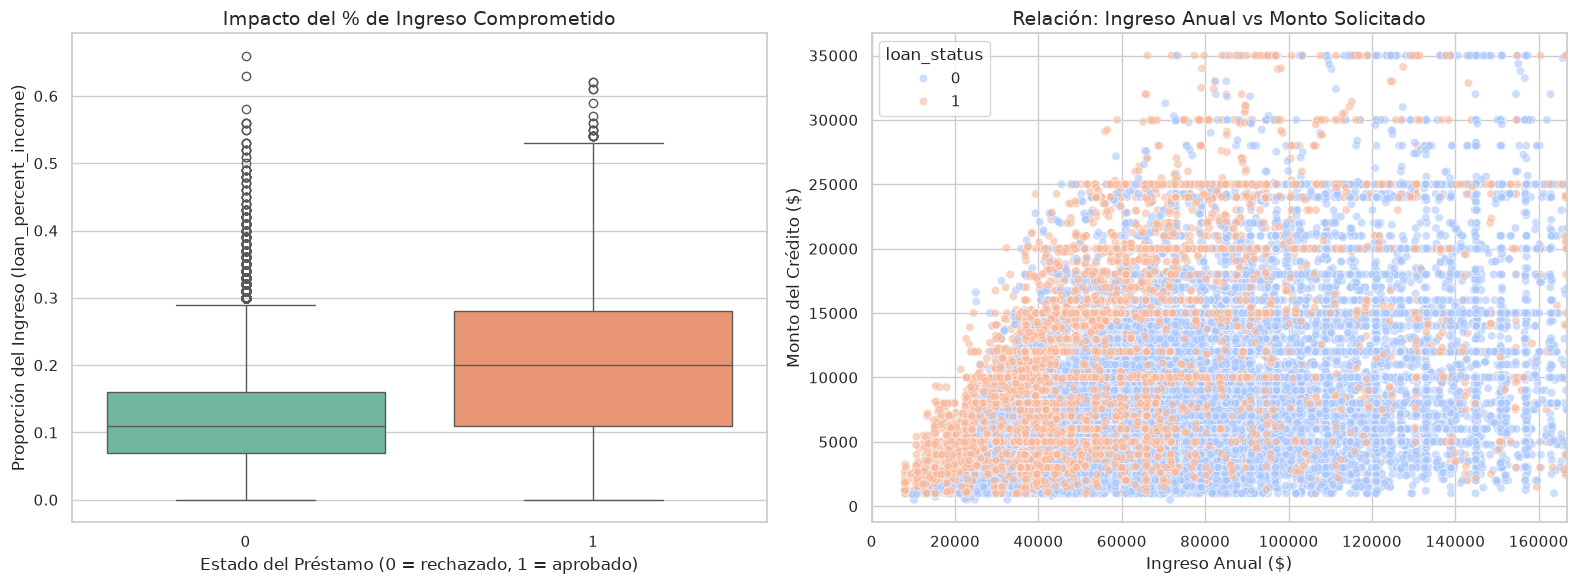

In [9]:


# Configurar el estilo visual
sns.set_theme(style="whitegrid")

# Crear una figura con dos subgráficos (1 fila, 2 columnas)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Nos ayuda a ver si el porcentaje del ingreso es un factor decisivo
sns.boxplot(
    data=df, 
    x='loan_status', 
    y='loan_percent_income', 
    palette='Set2', 
    ax=axes[0]
)
axes[0].set_title('Impacto del % de Ingreso Comprometido', fontsize=14)
axes[0].set_xlabel('Estado del Préstamo (0 = rechazado, 1 = aprobado)', fontsize=12)
axes[0].set_ylabel('Proporción del Ingreso (loan_percent_income)', fontsize=12)

# Nos ayuda a ver en qué zonas de dinero se aprueban o rechazan más créditos
sns.scatterplot(
    data=df, 
    x='person_income', 
    y='loan_amnt', 
    hue='loan_status', 
    palette='coolwarm', 
    alpha=0.6, # Transparencia para ver puntos superpuestos
    ax=axes[1]
)
axes[1].set_title('Relación: Ingreso Anual vs Monto Solicitado', fontsize=14)
axes[1].set_xlabel('Ingreso Anual ($)', fontsize=12)
axes[1].set_ylabel('Monto del Crédito ($)', fontsize=12)

# Limitar el eje X en ingresos muy altos para que la gráfica no se deforme por millonarios atípicos
axes[1].set_xlim(0, df['person_income'].quantile(0.95)) 

plt.tight_layout()
plt.show()

/tmp/ipykernel_886/3298354457.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_target.values, y=corr_target.index, palette='coolwarm', ax=axes[1])


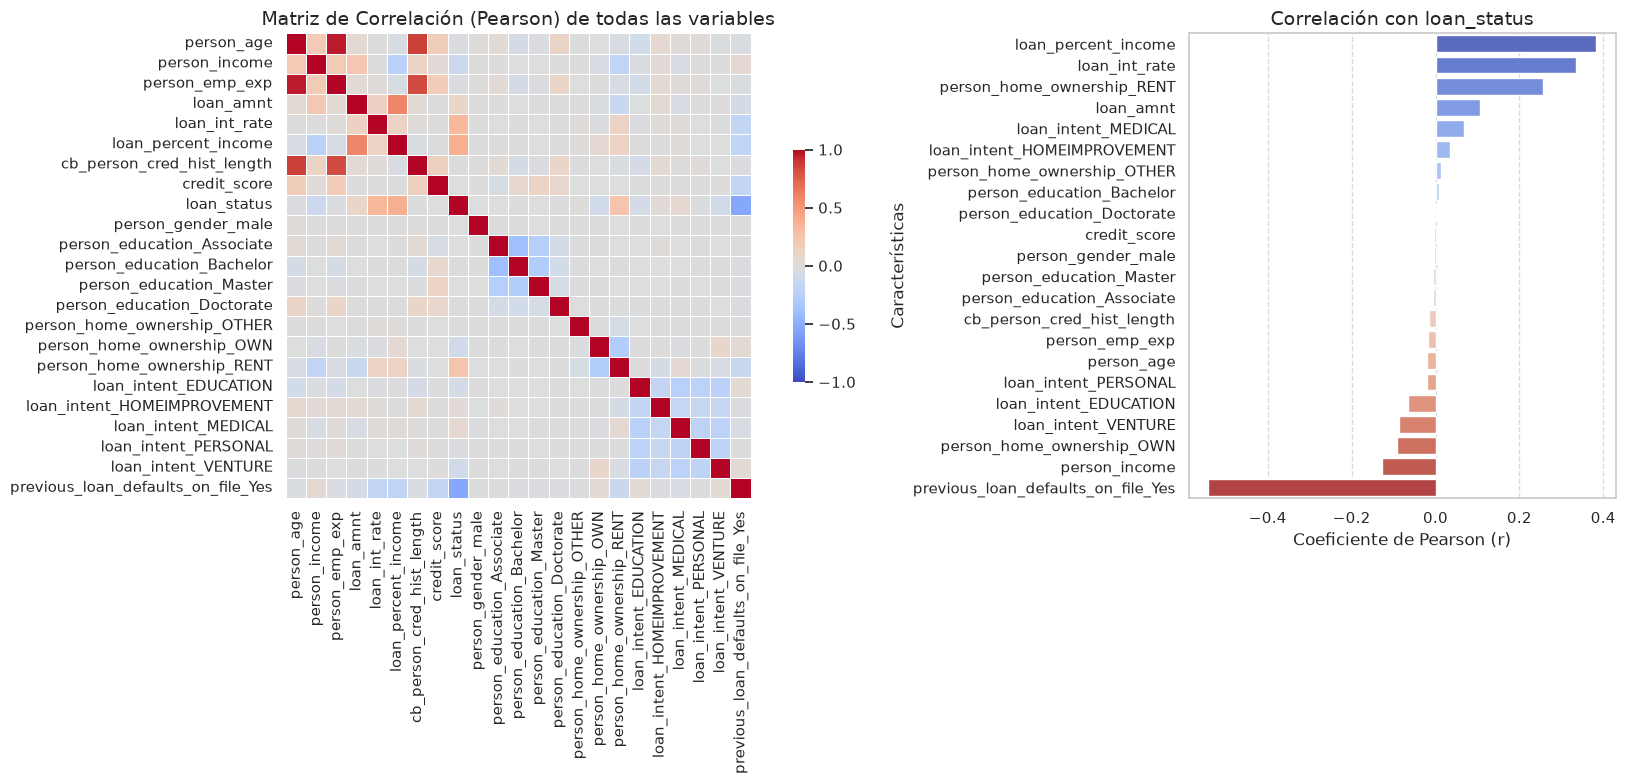

In [10]:
# aplicamos get_dummies para convertir las variables categóricas en variables dummy (one-hot encoding)
df_Train = pd.get_dummies(df_Train, drop_first=True) 

corr_matrix = df_Train.corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={'width_ratios': [2, 1]})

# grafico 1
sns.heatmap(
    corr_matrix, 
    cmap='coolwarm', 
    vmax=1, 
    vmin=-1, 
    center=0, 
    square=True, 
    linewidths=.5, 
    cbar_kws={"shrink": .5}, 
    ax=axes[0]
)
axes[0].set_title('Matriz de Correlación (Pearson) de todas las variables', fontsize=14)

# grafico 2
corr_target = corr_matrix['loan_status'].drop('loan_status').sort_values(ascending=False)

sns.barplot(x=corr_target.values, y=corr_target.index, palette='coolwarm', ax=axes[1])
axes[1].set_title('Correlación con loan_status', fontsize=14)
axes[1].set_xlabel('Coeficiente de Pearson (r)')
axes[1].set_ylabel('Características')
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

En la correlacion se puede apreciar las relaciones negativas y positivas respecto a la variable objetivo

En la matriz de correlacion hay una fuerte correlación positiva entre person_age (edad) y cb_person_cred_hist_length (longitud del historial crediticio). También hay una relación roja entre loan_amnt (monto del préstamo) y loan_percent_income (porcentaje del ingreso).

En la segunda imagen, las variables loan_percent_income, loan_int_rate (tasa de interés) y person_home_ownership_RENT (rentar casa) tienen los valores positivos más altos en el eje X, llegando hasta casi 0.4. Esto significa que a medida que estos valores aumentan, el loan_status tiende a moverse en la misma dirección, sin embargo, las variables previous_loan_defaults_on_file_Yes (tener incumplimientos previos) y person_income (ingresos) tienen los valores más negativos, extendiéndose hacia el -0.4 y -0.5 en el eje X. Esto indica que a medida que el ingreso aumenta o si hay incumplimientos, empujan el resultado del loan_status en la dirección opuesta


In [12]:
from cuml.svm import SVC as cuSVC

columnas_categoricas = ["person_gender", "person_education", "person_home_ownership", "loan_intent", "previous_loan_defaults_on_file"]

columnas_numericas = ["person_age", "person_income", "person_emp_exp", "loan_amnt", "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length", "credit_score"]

print(f"Columnas a escalar ({len(columnas_numericas)}):")
print(columnas_numericas)
print(f"\nColumnas categoricas ({len(columnas_categoricas)}):")
print(columnas_categoricas)

# El OneHotEncoder reemplaza a pd.get_dummies
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), columnas_numericas),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), columnas_categoricas),   
        ],
    remainder='passthrough'
)

logistic_clf = LogisticRegression(random_state=42, max_iter=1000)

sgd_clf = SGDClassifier(
    loss="log_loss",
    random_state=42
)

dummy_clf = DummyClassifier(strategy="most_frequent")

sgd_pipeline = Pipeline([
    ("preprocesamiento", preprocessor),
    ("model", sgd_clf)
])

logistic_pipeline = Pipeline([
    ("preprocesamiento", preprocessor),
    ("model", logistic_clf)
])

# 2. Definimos los pipelines del modelo SVM
pipeline_linear = Pipeline([
    ('preprocesamiento', preprocessor),
    ('svm', cuSVC(kernel='linear', random_state=42))
])

pipeline_poly = Pipeline([
    ('preprocesamiento', preprocessor),
    ('svm', cuSVC(kernel='poly', random_state=42))
])

pipeline_rbf = Pipeline([
    ('preprocesamiento', preprocessor),
    ('svm', cuSVC(kernel='rbf', random_state=42))
])

print("Pipelines construidos exitosamente.")

Columnas a escalar (8):
['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score']

Columnas categoricas (5):
['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']
Pipelines construidos exitosamente.


Se van a escalar las caracteristicas lineales ya que sus valores pueden ser medidos en cierto de un rango, y las categorias se les aplicara one hot encoder para convertiralas a binarias y tener un control mas estandar de sus valores

In [13]:

import time
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

def evaluar_modelo(nombre, modelo, X, y, cv, scoring):
    inicio_tiempo = time.time()
    print(f"Evaluando {nombre}...")
    resultados = cross_validate(modelo, X, y, cv=cv, scoring=scoring, n_jobs=-1, error_score='raise')
    fin_tiempo = time.time()
    return {
        "Modelo": nombre,
        "Tiempo de procesamiento": round(fin_tiempo - inicio_tiempo, 4),
        "Accuracy": f"{np.mean(resultados['test_accuracy']):.4f} (±{np.std(resultados['test_accuracy']):.4f})",
        "Precision": f"{np.mean(resultados['test_precision']):.4f} (±{np.std(resultados['test_precision']):.4f})",
        "Recall": f"{np.mean(resultados['test_recall']):.4f} (±{np.std(resultados['test_recall']):.4f})",
        "F1": f"{np.mean(resultados['test_f1']):.4f} (±{np.std(resultados['test_f1']):.4f})",
        "ROC-AUC": f"{np.mean(resultados['test_roc_auc']):.4f} (±{np.std(resultados['test_roc_auc']):.4f})"
    }

print("x TRAIN ANTES DE EVALUAR MODELOS")
res_dummy = evaluar_modelo("DummyClassifier", dummy_clf, X_train, y_train, cv, metricas)
res_sgd = evaluar_modelo("SGDClassifier", sgd_pipeline, X_train, y_train, cv, metricas)
res_lr = evaluar_modelo("LogisticRegression", logistic_pipeline, X_train, y_train, cv, metricas)
res_svm_linear = evaluar_modelo("SVM Lineal", pipeline_linear, X_train, y_train, cv, metricas)
res_svm_poly = evaluar_modelo("SVM Poly", pipeline_poly, X_train, y_train, cv, metricas)
res_svm_rbf = evaluar_modelo("SVM RBF", pipeline_rbf, X_train, y_train, cv, metricas)

df_resultados = pd.DataFrame([res_dummy, res_sgd, res_lr, res_svm_linear, res_svm_poly, res_svm_rbf])
display(df_resultados)

x TRAIN ANTES DE EVALUAR MODELOS
Evaluando DummyClassifier...


/mnt/c/archivos/docs maestria/practicas de machine learning/pratica svm diabetes/.venv-2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/mnt/c/archivos/docs maestria/practicas de machine learning/pratica svm diabetes/.venv-2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/mnt/c/archivos/docs maestria/practicas de machine learning/pratica svm diabetes/.venv-2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being 

Evaluando SGDClassifier...
Evaluando LogisticRegression...
Evaluando SVM Lineal...
Evaluando SVM Poly...
Evaluando SVM RBF...


,Modelo,Tiempo de procesamiento,Accuracy,Precision,Recall,F1,ROC-AUC
0,DummyClassifier,9.4018,0.7778 (±0.0000),0.0000 (±0.0000),0.0000 (±0.0000),0.0000 (±0.0000),0.5000 (±0.0000)
1,SGDClassifier,8.2218,0.8941 (±0.0020),0.7706 (±0.0123),0.7465 (±0.0260),0.7579 (±0.0091),0.9527 (±0.0020)
2,LogisticRegression,5.1186,0.8951 (±0.0014),0.7745 (±0.0056),0.7450 (±0.0100),0.7594 (±0.0041),0.9536 (±0.0017)
3,SVM Lineal,17.7824,0.8961 (±0.0018),0.7795 (±0.0053),0.7428 (±0.0092),0.7607 (±0.0050),0.9534 (±0.0017)
4,SVM Poly,13.8181,0.9100 (±0.0032),0.8671 (±0.0071),0.7029 (±0.0114),0.7764 (±0.0089),0.9581 (±0.0028)
5,SVM RBF,16.4716,0.9146 (±0.0026),0.8464 (±0.0071),0.7521 (±0.0104),0.7965 (±0.0068),0.9619 (±0.0025)


In [15]:
def graficar_matrices_confusion(modelos, X_train, y_train, cv, n_jobs=-1):
    n_modelos = len(modelos)
    # Define la cuadrícula dinámicamente (máximo 2 columnas por fila)
    columnas = 2 if n_modelos > 1 else 1
    filas = math.ceil(n_modelos / columnas)
    
    # Cambia esta línea:
    fig, axes = plt.subplots(filas, columnas, figsize=(8 * columnas, 5 * filas))
    
    # Asegurar que axes sea iterable aunque sea un solo modelo
    if n_modelos == 1:
        axes = [axes]
    elif filas > 1 or columnas > 1:
        axes = axes.flatten()
        
    etiquetas = ["Loan Not Approved (0)", "Loan Approved (1)"]
    df_y_score = pd.DataFrame(columns=["nombre", "y_scores"])

    for i, (nombre, pipeline) in enumerate(modelos.items()):
        print(f"============= Evaluando {nombre} =============")

        # Predicciones con validación cruzada
        if pipeline['method'] == 'predict_proba':
            y_scores = cross_val_predict(pipeline['pipeline'], X_train, y_train, cv=cv, method=pipeline['method'], n_jobs=n_jobs)[:, 1]

            # Convertimos probabilidades a clases (0 o 1) con umbral de 0.5
            y_pred = (y_scores >= 0.5).astype(int)
           
            nuevo_registro = pd.DataFrame([{"nombre": nombre, "y_scores": y_scores}])
            df_y_score = pd.concat([df_y_score, nuevo_registro], ignore_index=True)

        else:
            y_scores = cross_val_predict(pipeline['pipeline'], X_train, y_train, cv=cv, method=pipeline['method'], n_jobs=n_jobs)

            y_pred = (y_scores >= 0).astype(int)

            nuevo_registro = pd.DataFrame([{"nombre": nombre, "y_scores": y_scores}])
            df_y_score = pd.concat([df_y_score, nuevo_registro], ignore_index=True)

        
        cm = confusion_matrix(y_train, y_pred)
        # Graficar matriz
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=etiquetas)
        disp.plot(ax=axes[i], cmap='Blues', values_format='d', colorbar=False)
        axes[i].set_title(f'Matriz de Confusión - {nombre}')
        axes[i].grid(False)
        
    # Eliminar subgráficos vacíos si el número de modelos es impar
    for j in range(n_modelos, len(axes)):
        fig.delaxes(axes[j])
        
    plt.tight_layout(w_pad=4.0, h_pad=3.0)
    plt.show()
    return df_y_score

============= Evaluando SGDClassifier =============
============= Evaluando LogisticRegression =============
============= Evaluando SVM Lineal =============
============= Evaluando SVM Poly =============
============= Evaluando SVM RBF =============


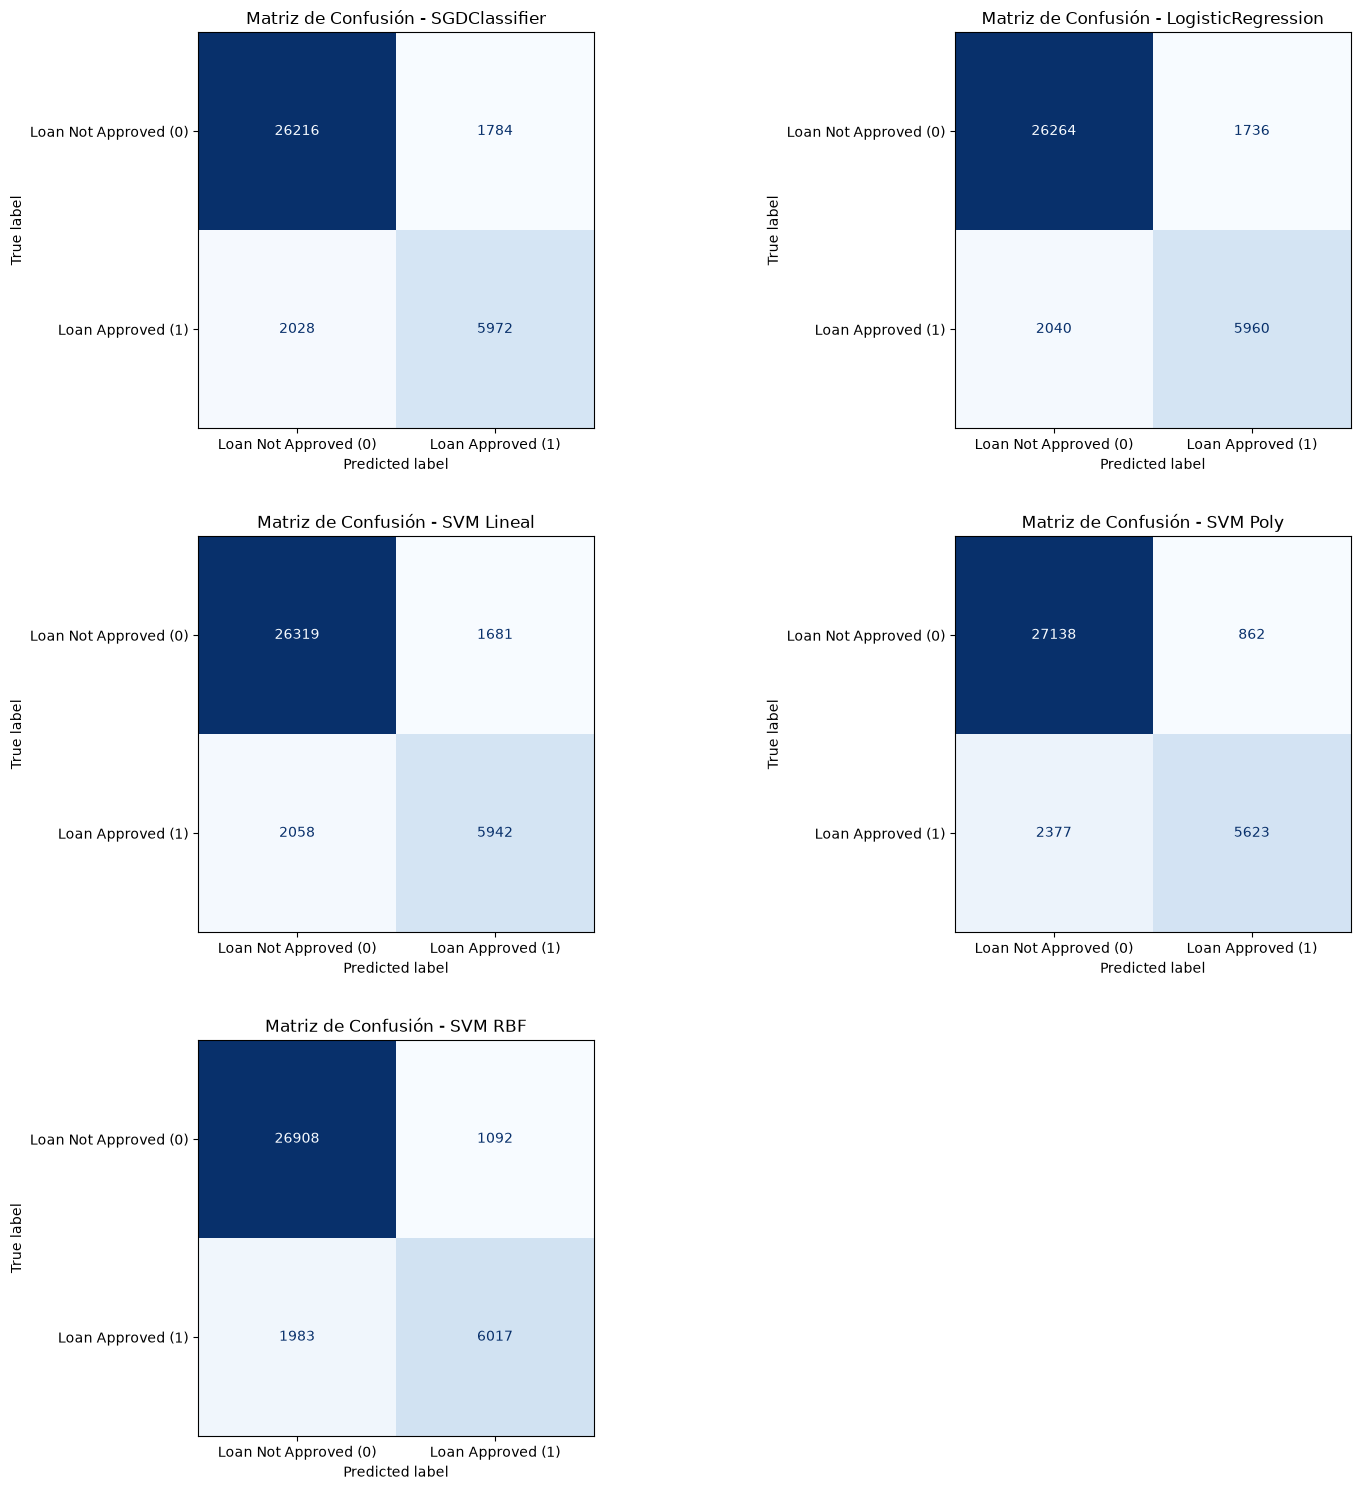

,nombre,y_scores
0,SGDClassifier,"[5.191949555208469e-06, 0.0015717088051091484,..."
1,LogisticRegression,"[1.926668485992185e-06, 0.0007813135728941235,..."
2,SVM Lineal,"[-8.70555025280465, -4.042098236362421, -6.503..."
3,SVM Poly,"[-2.7362010459221118, -1.4307181871871761, -2...."
4,SVM RBF,"[-2.4823700275890515, -2.3226306484163395, -2...."


In [16]:
# Crear diccionario con todos los pipelines a evaluar
mis_modelos = {
    'SGDClassifier': sgd_pipeline,
    'LogisticRegression': logistic_pipeline,
    'SVM Lineal': pipeline_linear,
    'SVM Poly': pipeline_poly,
    'SVM RBF': pipeline_rbf
}

mis_modelos2 = {
    'SGDClassifier': {
        'method': 'predict_proba',
        'pipeline': sgd_pipeline,
    },
    'LogisticRegression': {
        'method': 'predict_proba',
        'pipeline': logistic_pipeline,
    },
    'SVM Lineal': {
        'method': 'decision_function',
        'pipeline': pipeline_linear,
    },
    'SVM Poly': {
        'method': 'decision_function',
        'pipeline': pipeline_poly,
    },
    'SVM RBF': {
        'method': 'decision_function',
        'pipeline': pipeline_rbf,
    }
}


# Llama a la función pasando el diccionario
y_models_scores = graficar_matrices_confusion(mis_modelos2, X_train, y_train, cv=cv)
display(y_models_scores)

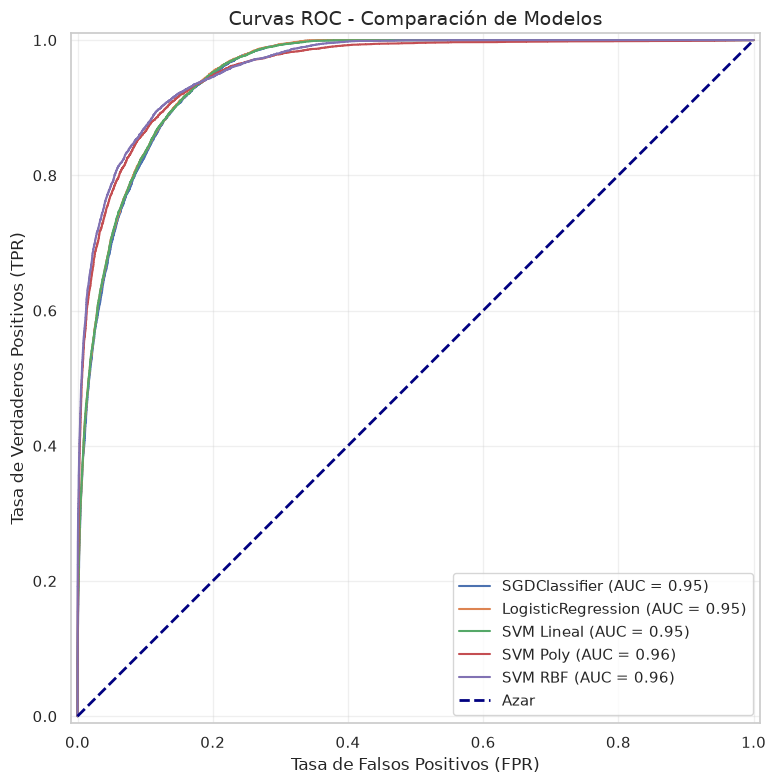

In [15]:
fig, ax = plt.subplots(figsize=(10, 8))

for index, row in y_models_scores.iterrows():
    # Usamos from_predictions asignando siempre el mismo 'ax' para sobreponerlas
    RocCurveDisplay.from_predictions(
        y_train,                # Etiquetas reales de tu set de entrenamiento
        row['y_scores'],        # Los scores que ya guardaste en la tabla[cite: 8]
        name=row['nombre'],     # El nombre del modelo para la leyenda[cite: 8]
        ax=ax                   # Parámetro clave: dibuja sobre el mismo gráfico
    )

# Agregar la línea diagonal de referencia (clasificador aleatorio)
ax.plot([0, 1], [0, 1], linestyle='--', color='navy', lw=2, label='Azar')

# Configuraciones estéticas finales
ax.set_title('Curvas ROC - Comparación de Modelos', fontsize=14)
ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax.grid(alpha=0.3)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    'svm__C': [0.01, 0.1, 1, 5], 
    'svm__gamma': ['scale', 'auto', 0.001, 0.01],
    'svm__class_weight': ['balanced']
}

pipeline_search = Pipeline([
    ('preprocesamiento', preprocessor),
    ('svm', cuSVC(kernel='rbf', random_state=42))
])

random_search = RandomizedSearchCV(
    pipeline_search, 
    param_distributions=param_distributions, 
    n_iter=15, 
    cv=5,     
    scoring='average_precision', 
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Iniciando optimización de hiperparámetros...")
random_search.fit(X_train, y_train) 

# 1. Extraer los resultados de la validación cruzada y convertirlos a DataFrame
df_cv_results = pd.DataFrame(random_search.cv_results_)

# 2. Seleccionar solo las columnas más útiles para la visualización
columnas_interes = [
    'rank_test_score', 
    'mean_test_score', 
    'std_test_score', 
    'param_svm__C', 
    'param_svm__gamma'
]
df_resultados_limpio = df_cv_results[columnas_interes].copy()

# 3. Renombrar las columnas para que sean más legibles
df_resultados_limpio.rename(columns={
    'rank_test_score': 'Ranking',
    'mean_test_score': 'ROC-AUC Medio',
    'std_test_score': 'Desviación Estándar',
    'param_svm__C': 'C (Regularización)',
    'param_svm__gamma': 'Gamma'
}, inplace=True)

# 4. Ordenar por el mejor score (Ranking 1)
df_resultados_limpio = df_resultados_limpio.sort_values(by='Ranking').reset_index(drop=True)

# 5. Mostrar la tabla 
print("\n--- Tabla de Resultados de Hiperparámetros ---")
display(df_resultados_limpio)

# Guardamos el mejor modelo para la fase final
modelo_final = random_search.best_estimator_

Iniciando optimización de hiperparámetros...
Fitting 5 folds for each of 15 candidates, totalling 75 fits

--- Tabla de Resultados de Hiperparámetros ---


,Ranking,ROC-AUC Medio,Desviación Estándar,C (Regularización),Gamma
0,1,0.888049,0.009000,5.00,auto
1,2,0.885413,0.008252,1.00,auto
2,3,0.882367,0.007603,1.00,scale
3,4,0.880044,0.007855,5.00,scale
4,5,0.879007,0.007381,5.00,0.01
5,6,0.872264,0.007613,1.00,0.01
6,7,0.871910,0.006141,0.10,auto
7,8,0.871734,0.006343,0.10,scale
8,9,0.859881,0.006134,0.10,0.01
9,10,0.856791,0.007082,5.00,0.001


=== Resultado usando RBF ===


,Accuracy,Precisión,Recall,F1
0,0.8733,0.651,0.927,0.7649


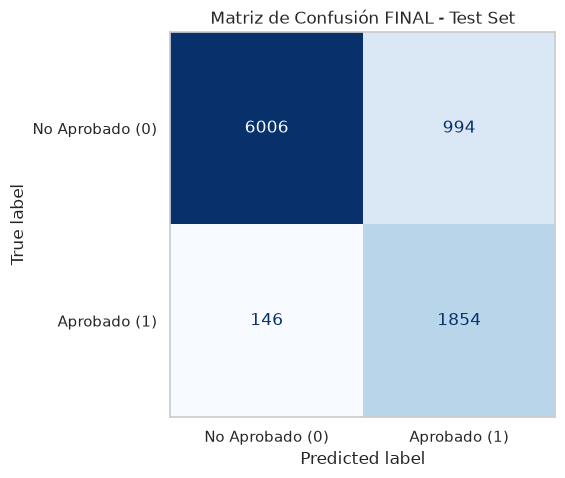

In [17]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix, f1_score, accuracy_score
print("=== Resultado usando RBF ===")
y_pred_default = modelo_final.predict(X_test)
metricas_default = {
    "Accuracy": round(accuracy_score(y_test, y_pred_default), 4),
    "Precisión": round(precision_score(y_test, y_pred_default), 4),
    "Recall": round(recall_score(y_test, y_pred_default), 4),
    "F1": round(f1_score(y_test, y_pred_default), 4)
}

# Convertir a DataFrame y mostrar
df_metricas_default = pd.DataFrame([metricas_default])
display(df_metricas_default)

cm_test = confusion_matrix(y_test, y_pred_default)
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=["No Aprobado (0)", "Aprobado (1)"])

fig, ax = plt.subplots(figsize=(6, 5))
disp_test.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title('Matriz de Confusión FINAL - Test Set')
ax.grid(False)
plt.show()

Resultado usando Linear Kernel

![Screenshot 2026-10-21 000056.png](<attachment:Screenshot 2026-10-21 000056.png>)
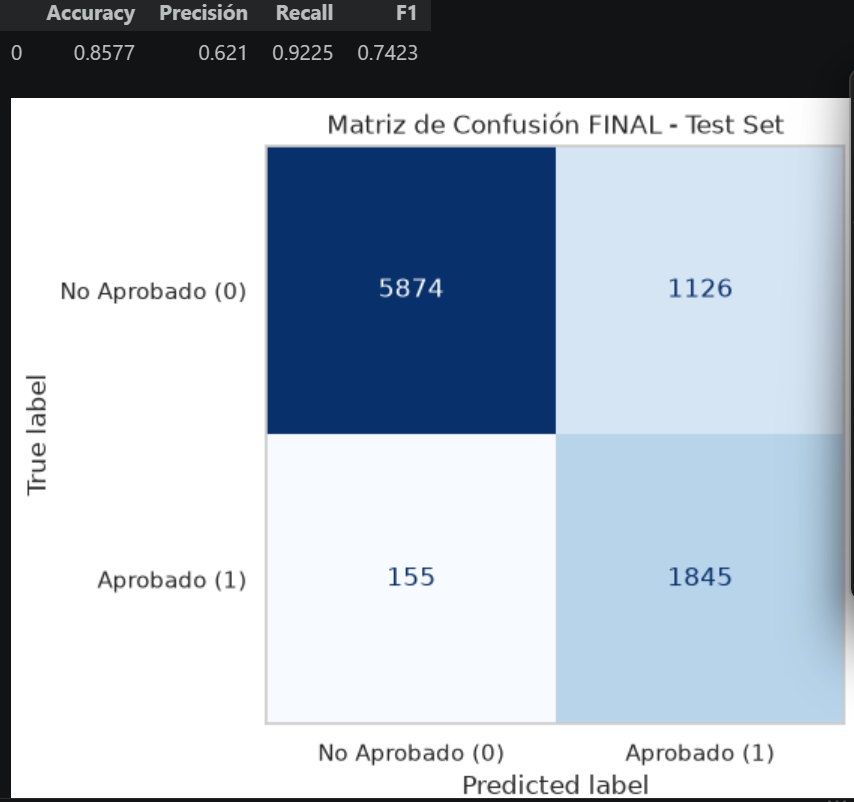

Resultado usando Polynomial con degree 2,3

![Screenshot 2026-10-21 001239.png](<attachment:Screenshot 2026-10-21 001239.png>)
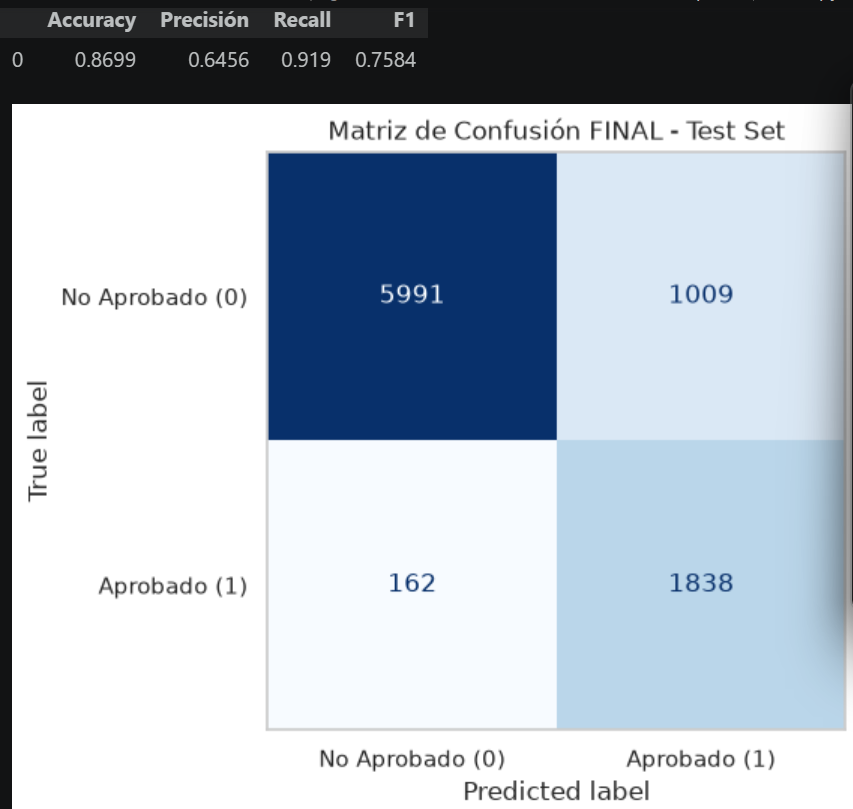

/mnt/c/archivos/docs maestria/practicas de machine learning/pratica svm diabetes/.venv-2/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


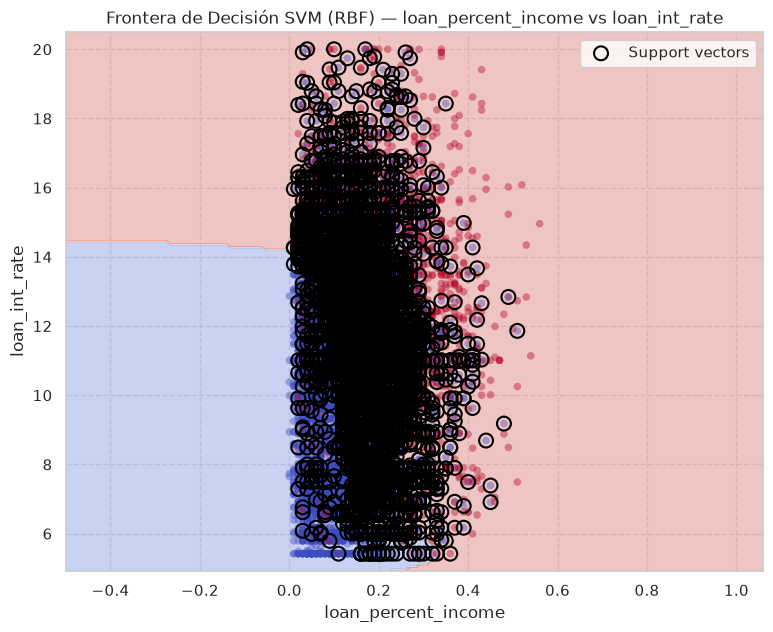

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

# 1. Elige los nombres de las 2 características que quieres visualizar (deben estar en tus columnas numéricas)
#loan_percent_income vs loan_int_rate
#person_income vs loan_amnt
#credit_score vs loan_int_rate
feat_x = 'loan_percent_income'       
feat_y = 'loan_int_rate'

# Extraemos los datos de prueba para estas dos columnas
X_subset_test = X_test[[feat_x, feat_y]].copy()
y_subset_test = y_test.copy()

# 2. Entrenamos un SVM rápido solo con estas 2 variables (para fines de visualización)
# Usamos los hiperparámetros que descubriste o los que quieras probar
clf_viz = SVC(kernel='rbf', C=5.0, gamma='auto', class_weight='balanced', random_state=42)
clf_viz.fit(X_subset_test, y_subset_test)

# 3. Creamos una malla (grid) para pintar el fondo de la gráfica (frontera de decisión)
x_min, x_max = X_subset_test[feat_x].min() - 0.5, X_subset_test[feat_x].max() + 0.5
y_min, y_max = X_subset_test[feat_y].min() - 0.5, X_subset_test[feat_y].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Predecimos en cada punto de la malla para colorear el fondo
Z = clf_viz.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 4. Dibujamos la gráfica
plt.figure(figsize=(9, 7))

# Pintar las regiones de decisión de fondo
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)

# Graficar los puntos del conjunto de prueba
scatter = plt.scatter(X_subset_test[feat_x], X_subset_test[feat_y], 
            c=y_subset_test, edgecolors='none', alpha=0.4, cmap=plt.cm.coolwarm, s=30)

# Resaltar los Vectores de Soporte
support_vectors = clf_viz.support_vectors_
plt.scatter(support_vectors[:, 0], support_vectors[:, 1], s=100, 
            facecolors='none', edgecolors='black', linewidths=1.5, label='Support vectors')

plt.xlabel(feat_x)
plt.ylabel(feat_y)
plt.title(f"Frontera de Decisión SVM (RBF) — {feat_x} vs {feat_y}")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

| Titulo de investigacion | Modelo | accuracy score | precision score | recall score | f1 score |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Data-Driven Loan Default Prediction: A Machine Learning Approach | Gradient Boosting | 0.8887 | N/A | 0.8021 | 0.8084 |
| Loan Default Prediction Using Ensemble Machine Learning Algorithms | Random Forest | 0.930 | 0.896 | 0.773 | 0.830 |
| | Gradient Boosting | 0.926 | 0.885 | 0.768 | 0.823 |
| | XGBoost | 0.932 | 0.890 | 0.789 | 0.837 |
| | LightGBM | 0.933 | 0.888 | 0.798 | 0.841 |
| Loan Approval Prediction Using Neural Networks | | 0.9100 | 0.8400 | 0.7400 | N/A |
| WQD7004 Group 7 Project Report: Loan Application Decision Classification | svm linear | 0.729 | 1.0 | 0.652 | 0.789 |
| | gbm | 0.729 | 1.0 | 0.6524 | 0.789 |
| | random forest | 0.729 | 1.0 | 0.6524 | 0.789 |
| | decision tree | 0.729 | 1.0 | 0.6524 | 0.789 |
| | logistic | 0.8448 | 0.972 | 0.824 | 0.892 |


Mis resultados

| Titulo de investigacion | Modelo | accuracy score | precision score | recall score | f1 score |
| :--- | :--- | :--- | :--- | :--- | :--- |
| WQD7004 Group 7 Project Report: Loan Application Decision Classification | svm linear | 0.857 | 0.621 | 0.922 | 0.742 |
| | SVM RBF | 0.873 | 0.651 | 0.927 | 0.764 |
| | SVM Poly | 0.869 | 0.645 | 0.919 | 0.758 |
| | logistic | 0.8994 | 0.789 | 0.747 | 0.7675 |
```eof

Preguntas

- ¿Sus resultados son comparables con los reportados en la literatura?
    si, ya que se hace uso del mismo dataset y en uno de ellas se usa un modelo svm linear el cual el resultado es diferente al mio y s epuede debatir el porque 
- ¿Los trabajos utilizan el mismo dataset?
    si
- ¿Utilizan el mismo número de características?
    si 
- ¿Utilizan la misma partición de datos?
    No, Aunque la práctica estándar de dividir el conjunto en entrenamiento y prueba (por ejemplo, con proporciones de 80/20 o 70/30) es común, los porcentajes exactos de división y, sobre todo, las semillas aleatorias (random_state) varían en cada estudio, lo que genera distribuciones distintas en los conjuntos de evaluación.
- ¿Utilizan Cross-Validation o un Test independiente?
    Existe una combinación de ambas estrategias en la literatura. Los trabajos más robustos implementan validación cruzada (como $k$-fold de 3, 5 o 10 particiones) combinada con una búsqueda de hiperparámetros (como RandomizedSearchCV), reservando finalmente un conjunto de prueba independiente para la evaluación final y evitar el sobreajuste.
- ¿Existen diferencias en preprocesamiento?
    Sí, son significativas. Aunque la mayoría coincide en realizar codificación de variables categóricas (como One-Hot Encoding o Label Encoding) y normalización numérica (StandardScaler), la diferencia crítica radica en cómo manejan el desbalance de clases. Algunos estudios implementan técnicas de sobremuestreo sintético como SMOTE o variantes avanzadas (SMOTE+ENN), mientras que otros optan por ajustar los pesos de las clases (class_weight='balanced') o aplicar umbrales de decisión sensibles al costo operativo.
- ¿Es válido comparar directamente las métricas?
    no tanto que los modelos operan bajo distribuciones de datos diferentes, si se maneja un grado de desbalance distinto o si se evalúan métricas que responden a prioridades de negocio opuestas
- ¿Qué diferencias metodológicas podrían explicar resultados superiores o inferiores?
    Varia ya que hay diferencia en la seleccion de modelos, optimizacion de hiperparametros y el como se maneje el desvalance